# Puntos Agrícolas

En esta libreta exploraremos los puntos agrícolas de las cartas de uso de suelo y vegetación.

## Mapa de México

Comenzaremos extrayendo la división municipal de México.


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

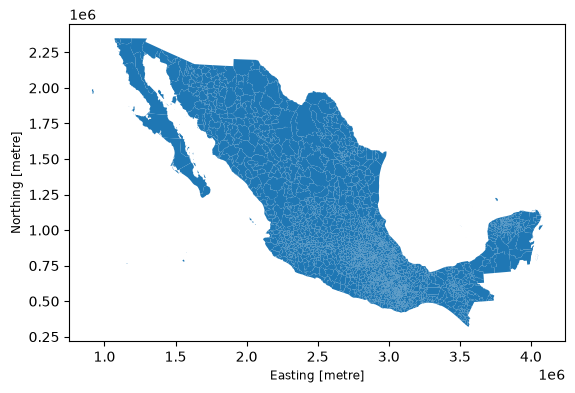

In [1]:
from scripts.config import PRELOADS, DATA_DIR
from zipfile import ZipFile
import geopandas as gpd
import os

MAPS_ROUTE = DATA_DIR / "raw" / "INEGI"
MEXICO = PRELOADS['MAPA GENERAL']

with ZipFile(MEXICO, "r") as mexico_map:
    mexico_map.extractall(MAPS_ROUTE)

mexico = gpd.read_file(MAPS_ROUTE / "Mexico" / "conjunto_de_datos" / "00mun.shp")
mexico.plot()

Como ejemplon lo aplicaremos a un estado del pais. 

In [57]:
selected_area = 0  # Aguascalientes
selected_area = f"0{selected_area}" if 0 < selected_area < 10 else str(selected_area)
# display(mexico)
map_area = mexico[mexico['CVE_ENT'] == selected_area] if selected_area != "0" else mexico.copy()
map_area

,CVEGEO,CVE_ENT,CVE_MUN,NOMGEO,geometry
0,01001,01,001,Aguascalientes,"POLYGON ((2488980.227 1117358.447, 2489013.495..."
1,01008,01,008,San José de Gracia,"POLYGON ((2453326.553 1143576.423, 2453363.325..."
2,01011,01,011,San Francisco de los Romo,"POLYGON ((2483638.349 1120034.022, 2483946.175..."
3,01009,01,009,Tepezalá,"POLYGON ((2481826.447 1149055.253, 2481589.222..."
4,01007,01,007,Rincón de Romos,"POLYGON ((2476760.231 1150329.046, 2476783.634..."
...,...,...,...,...,...
2473,32004,32,004,Benito Juárez,"POLYGON ((2336381.078 1064884.55, 2336405.02 1..."
2474,32043,32,043,Susticacán,"POLYGON ((2380699.092 1186256.441, 2380731.393..."
2475,32042,32,042,Sombrerete,"POLYGON ((2323463.845 1340295.088, 2323485.623..."
2476,32014,32,014,General Francisco R. Murguía,"POLYGON ((2395056.891 1381032.418, 2395060.211..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

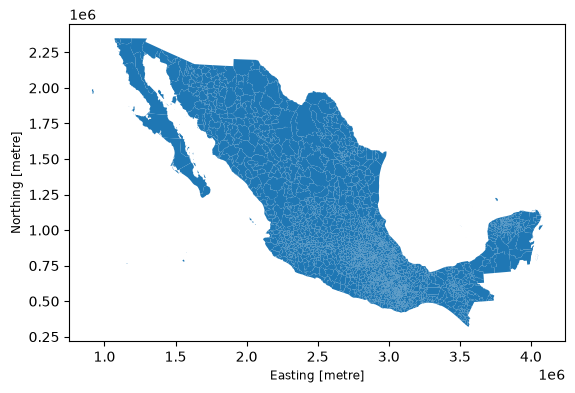

In [58]:
map_area.plot()


## Serie I
Comenzaremos con la Serie 1. Extraeremos los datos e iremos complementando con el resto de Series.

In [4]:
MAPS_FOLDER = DATA_DIR / "pure" / "INEGI"
maps = os.listdir(MAPS_FOLDER)

with ZipFile(MAPS_FOLDER / maps[0], 'r') as file:
    os.makedirs(MAPS_ROUTE / "m1", exist_ok=True)
    file.extractall(MAPS_ROUTE / "m1")


Una vez tengamos la información. Mostramos los puntos.

<Axes: xlabel='x', ylabel='y'>

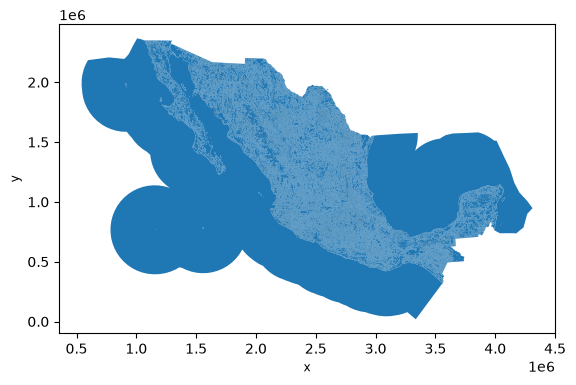

In [6]:
import geopandas as gpd

serie1_path = "/home/dusty/Documents/Repositories/proyecto_agronomia_Q/data/raw/INEGI/m1/conjunto_de_datos/us250s1v_lcc.shp"
serie1 = gpd.read_file(serie1_path)
serie1.plot()

In [7]:
serie1.crs  # Revisamos el formato CRS del mapa

Una vez cargado el mapa. Veremos los tipos de suelos existentes

In [8]:
serie1['ENTIDAD'].unique().tolist()

['CUERPO DE AGUA',
 'PASTIZAL',
 'OTROS TIPOS DE VEGETACION',
 'LOCALIDAD',
 'AREA AGRICOLA',
 'BOSQUE',
 'MATORRAL',
 'AREA SIN VEGETACION',
 'SELVA']

Entonces, en la serie 1 vamos a filtrar por los valores de área agrícola.

In [9]:
agro1 = serie1[serie1['ENTIDAD'] == "AREA AGRICOLA"]
agro1.shape

(30276, 16)

Vemos que al hacer el filtro tenemos más de 30,000 regiones agrícolas.

Index(['AREA', 'PERIMETER', 'US250S1V_', 'US250S1V_I', 'FC', 'CLAVEFOT',
       'ENTIDAD', 'TIPO', 'FISONOMIA', 'VEG_SEC', 'EROSION', 'CULT_PRI',
       'CULT_SEC', 'CULT_TER', 'OID', 'geometry'],
      dtype='str')


<Axes: xlabel='x', ylabel='y'>

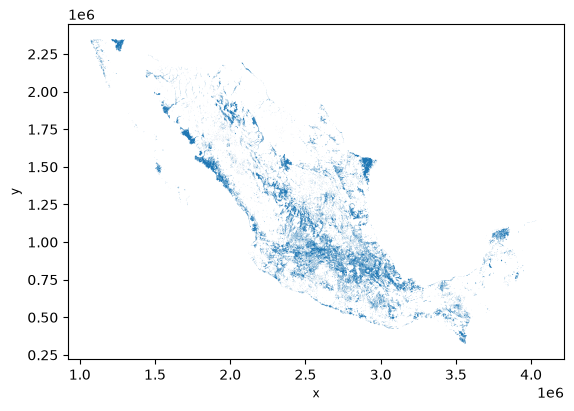

In [10]:
print(agro1.columns)
agro1.plot()

In [11]:
print(agro1['VEG_SEC'].unique())
print(agro1['EROSION'].unique())
print(agro1['CLAVEFOT'].unique())
print(agro1['FISONOMIA'].unique())
agro1_model = agro1.drop(columns=['US250S1V_', 'US250S1V_I', "FC", 'VEG_SEC', 'OID', 'FISONOMIA'])

<ArrowStringArray>
['no aplicable']
Length: 1, dtype: str
<ArrowStringArray>
['sin erosion apreciable', 'con erosion apreciable']
Length: 2, dtype: str
<ArrowStringArray>
[   'TA',    'RA',   '[R]',   'RAP',    'RP',   'TAP',   'RPA',  'E-TA',
    'RS',   'RAS',   'RSA',  'RPAS',  'RAPS',   'RPS',    'HA',   'ReA',
    'TP', 'E-[R]',  'RSAP',  'RASP',  'RPSA',   'TPA',   'TSA',   'TAS',
    'TS',   'RSP',  'TASP',  'TSAP',   'TSP',   'TPS',  'TPAS',  'TAPS',
  'TSPA',   'HAP',   'HPA',    'HP',   'HSA',    'HS',   'HAS', 'E-TAP',
  'ReAS', 'E-RSA',   'HSP', 'E-RAS',   'HPS',  'E-TP',   'ReP', 'E-TPA',
  'TPSA',   'ReS',  'ReAP',  'RSPA']
Length: 52, dtype: str
<ArrowStringArray>
['no aplicable']
Length: 1, dtype: str


Ahora, filtraremos con el mapa de zonas agricolas.

/home/dusty/Documents/Repositories/proyecto_agronomia_Q/.venv/lib/python3.14/site-packages/geopandas/geodataframe.py:2981: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:6372
Right CRS: None

  return geopandas.overlay(


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

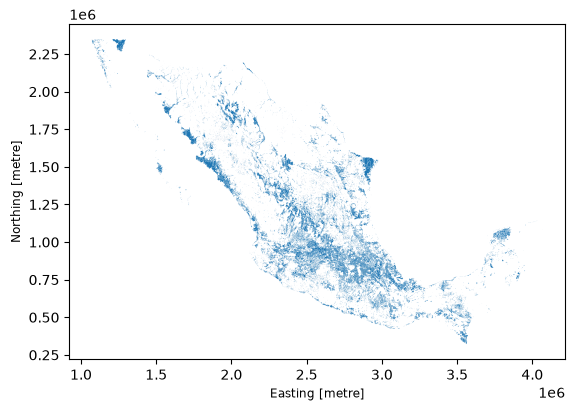

In [59]:
agro_map = map_area.overlay(agro1_model, how="intersection")
agro_map.plot()

Para la selección de puntos vamos a partir de las coordenadas esfericas,

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

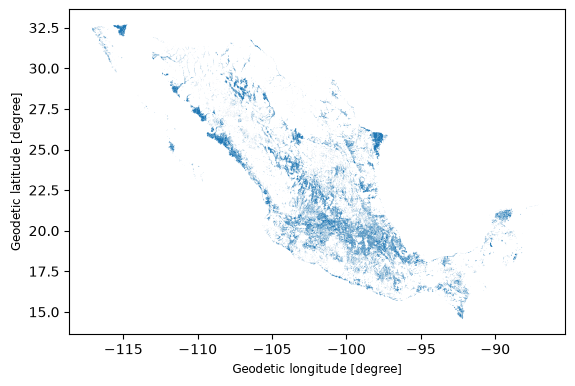

In [60]:
agro_model = agro_map.copy().to_crs(epsg="4326")
agro_model.plot()

Luego, revisareos los puntos que definen las celdas. Para ello tomaremos como ejemplo una de las variables del modelo.

In [61]:
import pandas as pd

temp_mexico = pd.read_parquet("/home/dusty/Documents/Repositories/proyecto_agronomia_Q/data/interm/NASA/serie_I/T2M.parquet")
temp_mexico

,time,lat,lon,value,param,units,serie
0,1981-01-01,14.0,-118.750,24.950012,T2M,C,I
1,1981-01-01,14.0,-118.125,25.020020,T2M,C,I
2,1981-01-01,14.0,-117.500,25.119995,T2M,C,I
3,1981-01-01,14.0,-116.875,25.270020,T2M,C,I
4,1981-01-01,14.0,-116.250,25.380005,T2M,C,I
...,...,...,...,...,...,...,...
754450,1981-12-31,33.0,-88.750,8.359985,T2M,C,I
754451,1981-12-31,33.0,-88.125,7.369995,T2M,C,I
754452,1981-12-31,33.0,-87.500,6.479980,T2M,C,I
754453,1981-12-31,33.0,-86.875,5.489990,T2M,C,I


Crearemos la malla que utilizo para la extracción de los datos a paritr de nuestra región.

((np.float64(-118.63202268412914), np.float64(-85.29110702974694)),
 (np.float64(13.64895907373384), np.float64(33.624133194817645)))

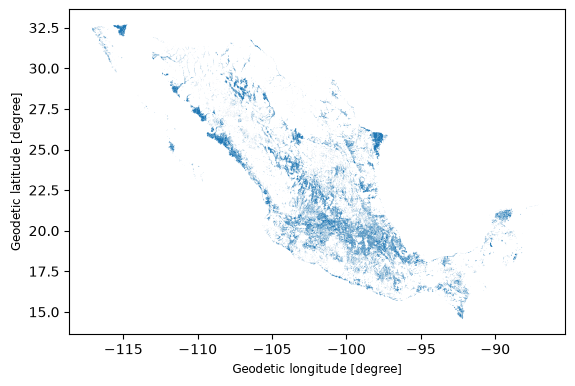

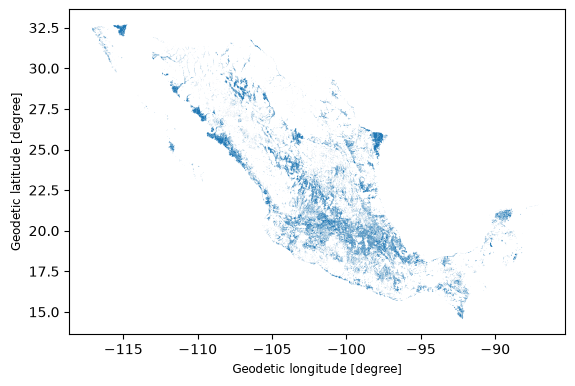

In [62]:
model_x, model_y = agro_model.plot().get_xlim(), agro_model.plot().get_ylim()
model_x, model_y

In [63]:
model_grid = temp_mexico[temp_mexico["lon"].between(model_x[0], model_x[1])]
model_grid = model_grid[model_grid["lat"].between(model_y[0], model_y[1])]
model_grid

,time,lat,lon,value,param,units,serie
1,1981-01-01,14.0,-118.125,25.020020,T2M,C,I
2,1981-01-01,14.0,-117.500,25.119995,T2M,C,I
3,1981-01-01,14.0,-116.875,25.270020,T2M,C,I
4,1981-01-01,14.0,-116.250,25.380005,T2M,C,I
5,1981-01-01,14.0,-115.625,25.590027,T2M,C,I
...,...,...,...,...,...,...,...
754450,1981-12-31,33.0,-88.750,8.359985,T2M,C,I
754451,1981-12-31,33.0,-88.125,7.369995,T2M,C,I
754452,1981-12-31,33.0,-87.500,6.479980,T2M,C,I
754453,1981-12-31,33.0,-86.875,5.489990,T2M,C,I


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

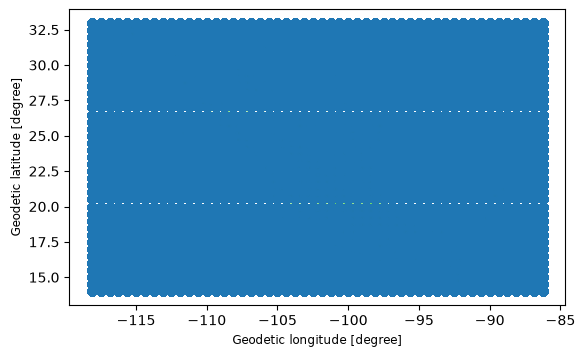

In [64]:
import matplotlib.pyplot as plt

model_lgrid = gpd.GeoSeries(gpd.points_from_xy(model_grid['lon'], model_grid['lat']))

fig_mgrid, ax = plt.subplots()
agro_model.plot(ax = ax, color="limegreen")
model_lgrid.plot(ax=ax)

A partir de ella vamos a formar un conjunto de puntos. A partir de los centros

Total de puntos (199, 15)


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

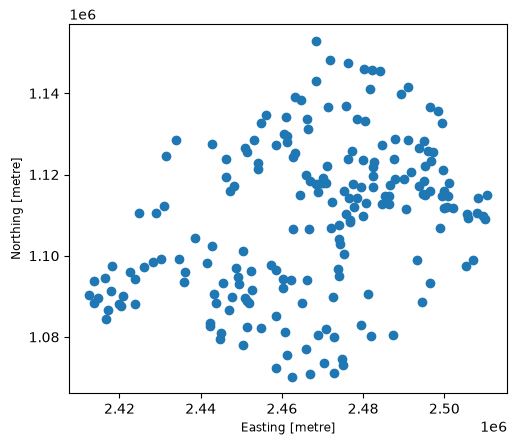

In [13]:
import matplotlib.pyplot as plt

agro_map['CENTRO'] = agro_map['geometry'].apply(lambda x: x.centroid)
print("Total de puntos", agro_map.shape)
agro_map['CENTRO'].plot()

Notemos que tenemos muchos puntos en uno de los estados más pequeños. Entonces, lo que haremos será a partir de los tipos de suelo vamos a disminuirlos.

In [14]:
agro_map['CULT_PRI'].unique()

<ArrowStringArray>
['anual', 'permanente', 'semipermanente']
Length: 3, dtype: str

Notemos que los puntos se clasifican en 3 tipos según su cultivo principal. Anual, permanente y semipermamente.Ejemplificaremos con la agricultura anual. 

CULT_PRI
anual             85.929648
permanente        12.562814
semipermanente     1.507538
Name: CVE_MUN, dtype: float64
Agricultura Anual 171


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

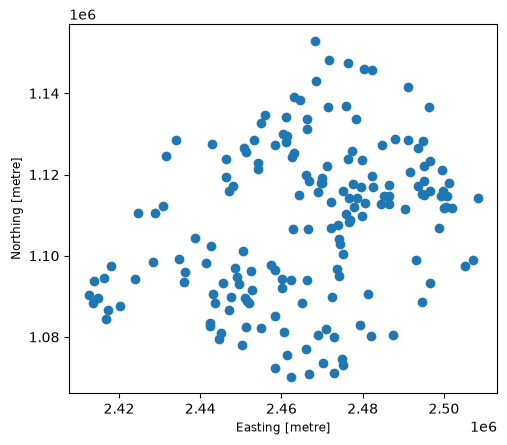

In [15]:
agro_stats = agro_map.groupby('CULT_PRI')['CVE_MUN'].count()
print(agro_stats / agro_map.shape[0] * 100)

agro_anual= agro_map[agro_map['CULT_PRI']=="anual"]
print("Agricultura Anual", agro_anual.shape[0])
agro_anual['CENTRO'].plot()

Vamos a procurar quitar los puntos de fomra que se abarque la mayor area posible. Para ello debenmos definir una distancia minma, que llamaremos $\delta$, bajo la siguiente regla. La distancia entre dos puntos debe ser mayor a $\delta$. Para ello, primero vamos a calcular la distancia minima entre 2 puntos. 

In [16]:
import scipy

anual_points = agro_anual[['CVEGEO', 'CENTRO']]
anual_points

,CVEGEO,CENTRO
0,01001,POINT (2466182.546 1094026.644)
1,01001,POINT (2486438.911 1112827.004)
2,01001,POINT (2480614.619 1112953.795)
3,01001,POINT (2486467.441 1114762.633)
4,01001,POINT (2477836.195 1112093.024)
...,...,...
189,01002,POINT (2499366.663 1114753.742)
190,01002,POINT (2499837.971 1115877.152)
192,01002,POINT (2500796.028 1114684.119)
193,01002,POINT (2499942.519 1111653.975)


In [17]:
import numpy as np
from scipy.spatial import cKDTree

# Asumiendo que la columna se llama "puntos"
coords = np.array([p.coords[0] for p in anual_points["CENTRO"]])  # (x, y) en metros

# Pares más cercanos (cada punto con su vecino más cercano)
tree = cKDTree(coords)
distancias, indices = tree.query(coords, k=2)   # k=2: el punto mismo + su vecino

# Excluir la distancia a sí mismo (distancia 0)
distancias = distancias[:, 1]
indices = indices[:, 1]

i_min = np.argmin(distancias)
par_minimo = (i_min, indices[i_min])
dmin = distancias[i_min]

# El par con la distancia mínima
print(f"Distancia mínima: {dmin:.2f} m")
print(f"Puntos: {anual_points.index[i_min]} y {anual_points.index[indices[i_min]]}")

Distancia mínima: 434.92 m
Puntos: 65 y 101


Entonces procuraremos que $\delta>435$ para minimizar el numero de puntos. Para ello, primero veremos cuantos puntos hay por municipios. 

In [18]:
agro_anual.value_counts('CVEGEO')

CVEGEO
01001    43
01002    23
01005    19
01003    19
01008    17
01011    13
01007    11
01010    10
01006     9
01009     4
01004     3
Name: count, dtype: int64

La regla que usaremos es tomar el punto más cercano al centro del municipio para intentar partir de puntos aislados. 

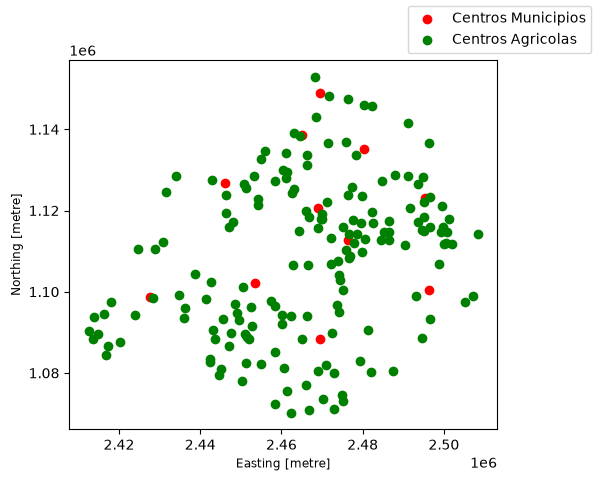

In [19]:
map_area['CENTRO'] = map_area['geometry'].apply(lambda x: x.centroid)
municipal_points = map_area[['CVEGEO','CENTRO']]
area, ax = plt.subplots()

map_area['CENTRO'].plot(ax=ax, label="Centros Municipios", color="red")
agro_anual['CENTRO'].plot(ax=ax, label="Centros Agricolas", color="green")
area.legend()

In [20]:
import pandas as pd


distances = pd.DataFrame(index=municipal_points['CENTRO'], columns=anual_points['CENTRO'])
distances.index.name = "Municipios"
for c in distances.columns:
    distances[c] = [c.distance(p2) for p2 in distances.index]

selected_points = distances.idxmin(axis=1).tolist()
selected_points

[<POINT (2472492.703 1089905.081)>,
 <POINT (2446288.239 1123922.903)>,
 <POINT (2477836.195 1112093.024)>,
 <POINT (2478455.199 1133639.734)>,
 <POINT (2464689.275 1138289.392)>,
 <POINT (2470017.662 1119151.181)>,
 <POINT (2471835.645 1148278.6)>,
 <POINT (2450450.218 1101152.833)>,
 <POINT (2493162.41 1098999.363)>,
 <POINT (2428298.45 1098464.305)>,
 <POINT (2495207.449 1122163.926)>]

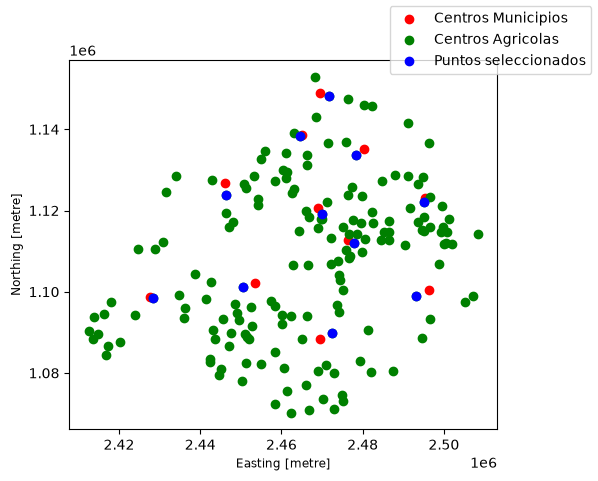

In [21]:
select_process, ax = plt.subplots()
map_area['CENTRO'].plot(ax=ax, label="Centros Municipios", color="red")
selected_centro = gpd.GeoSeries(selected_points)
agro_anual['CENTRO'].plot(ax=ax, label="Centros Agricolas", color="green")
selected_centro.plot(ax=ax, color="blue", label="Puntos seleccionados")
select_process.legend()

Con los primeros puntos. Quitaremos todos los puntos tales que la distancia sea menor a $\delta$. 

Puntos Totales 171
Puntos eliminados 51
Factor de Reducción 29.82456140350877


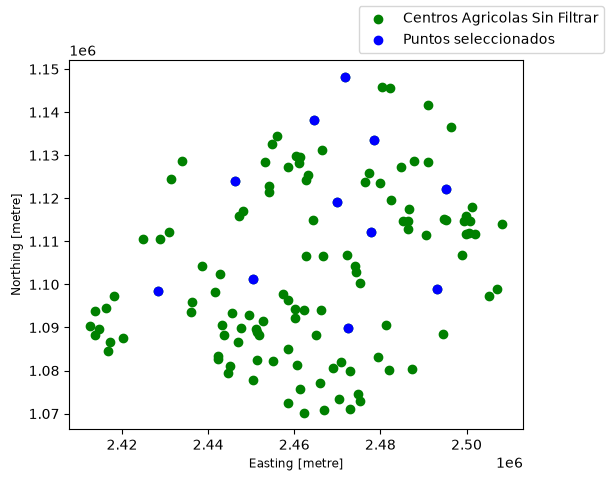

In [22]:
delta = 7_000 # Distancia de 10_000 metros
filter_points = []
for critic_point in selected_points:
    for idp in anual_points.index:
        point = anual_points.loc[idp, "CENTRO"]
        dis = critic_point.distance(point)
        if dis < delta and point != critic_point:
            filter_points.append(idp)
print("Puntos Totales", len(anual_points))
print("Puntos eliminados", len(filter_points))
print("Factor de Reducción", len(filter_points) / len(anual_points) * 100)
select_process, ax = plt.subplots()
selected_centro = gpd.GeoSeries(selected_points)
test = anual_points.drop(index = filter_points)
test['CENTRO'].plot(ax=ax, label="Centros Agricolas Sin Filtrar", color="green")
selected_centro.plot(ax=ax, color="blue", label="Puntos seleccionados")
select_process.legend()



<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

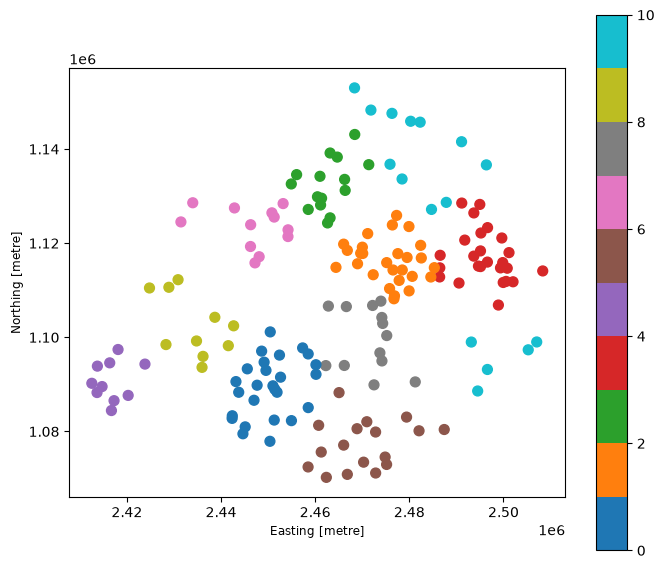

In [36]:
from sklearn.cluster import KMeans
import numpy as np

# Coordenadas de tus puntos (EPSG:6372 → metros)
coords = np.array([p.coords[0] for p in anual_points["CENTRO"]])

# Elegir K: prueba varios y evalúa inercia
kmeans = KMeans(n_clusters=municipal_points.shape[0], random_state=42, n_init=10)
labels = kmeans.fit_predict(coords)

# Agregar la etiqueta al GeoDataFrame y graficar por cluster
pts_adelgazados = anual_points.copy()
pts_adelgazados["cluster"] = labels

pts_adelgazados.set_geometry("CENTRO").plot(
    column="cluster", legend=True, cmap="tab10", figsize=(8, 8), markersize=50
)

Clusters encontrados: 2
Puntos de ruido: 55


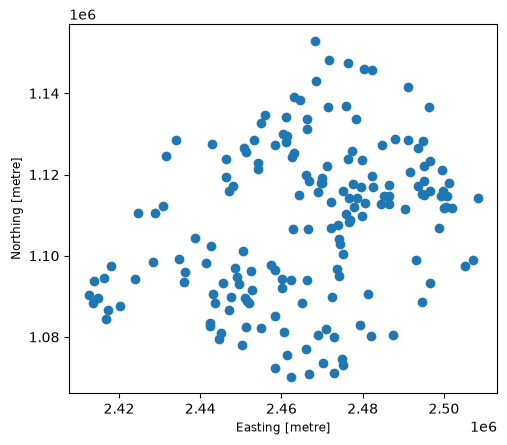

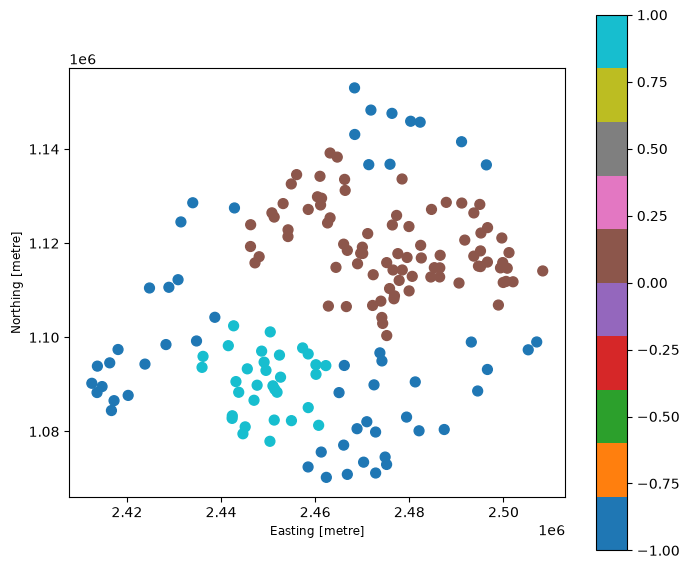

In [35]:
from sklearn.cluster import DBSCAN

anual_points['CENTRO'].plot()

min_sample = anual_points.shape[0] // municipal_points.shape[0]


dbscan = DBSCAN(eps=10_000, min_samples=min_sample).fit(coords)
labels = dbscan.labels_


anual_points["cluster"] = labels

anual_points.set_geometry("CENTRO").plot(
    column="cluster", legend=True, cmap="tab10", figsize=(8, 8), markersize=50
)

print(f"Clusters encontrados: {len(set(labels)) - (1 if -1 in labels else 0)}")
print(f"Puntos de ruido: {(labels == -1).sum()}")



In [50]:
import numpy as np
import geopandas as gpd
import shapely
from shapely.geometry import Point
from scipy.spatial import cKDTree

union = agro_anual.union_all()   # disuelve todas las zonas en una geometría
R = 2500      # radio de iluminación (m)
D_MIN = 8000   # separación mínima entre focos (m)
PASO = R / 4   # resolución del muestreo (~2.5 km)

minx, miny, maxx, maxy = union.bounds
xs = np.arange(minx, maxx, PASO)
ys = np.arange(miny, maxy, PASO)
X, Y = np.meshgrid(xs, ys)

# Solo puntos dentro del área agrícola
mask = shapely.contains_xy(union, X.ravel(), Y.ravel())
muestras = np.column_stack([X.ravel()[mask], Y.ravel()[mask]])
print(f"{len(muestras)} puntos de muestreo")

5368 puntos de muestreo


In [51]:
tree = cKDTree(muestras)

# Para cada candidato, qué muestras ilumina (a <= R)
cobertura = tree.query_ball_point(muestras, r=R)

cubiertos = np.zeros(len(muestras), dtype=bool)
seleccionados = []

# Lazy greedy con heap (las ganancias solo decrecen)
import heapq
heap = [(-len(c), i) for i, c in enumerate(cobertura)]
heapq.heapify(heap)

while heap and not cubiertos.all():
    negg, i = heapq.heappop(heap)
    ganancia = np.count_nonzero(~cubiertos[cobertura[i]])
    if ganancia == 0:
        continue
    if -negg > ganancia:                      # entrada vieja → recalcular y reinsertar
        heapq.heappush(heap, (-ganancia, i))
        continue
    # Restricción: >= D_MIN de los ya seleccionados
    if seleccionados:
        d = np.min(np.linalg.norm(muestras[seleccionados] - muestras[i], axis=1))
        if d < D_MIN:
            continue                          # candidato prohibido, se descarta
    seleccionados.append(i)
    cubiertos[cobertura[i]] = True

focos = muestras[seleccionados]
print(f"{len(focos)} focos necesarios")

53 focos necesarios


In [52]:
import geopandas as gpd
from shapely.geometry import Point


# focos = muestras[seleccionados]  → array (n, 2) de coordenadas x, y
gdf_focos = gpd.GeoDataFrame(
    {"id": range(len(focos))},
    geometry=[Point(x, y) for x, y in focos],
    crs=anual_points['CENTRO'].crs
)

# Verificar
print(gdf_focos.head())
print(gdf_focos.shape)

   id                     geometry
0   0  POINT (2484152.718 1082540)
1   1  POINT (2490402.718 1087540)
2   2  POINT (2464777.718 1093165)
3   3  POINT (2493527.718 1095040)
4   4  POINT (2498527.718 1101290)
(53, 2)


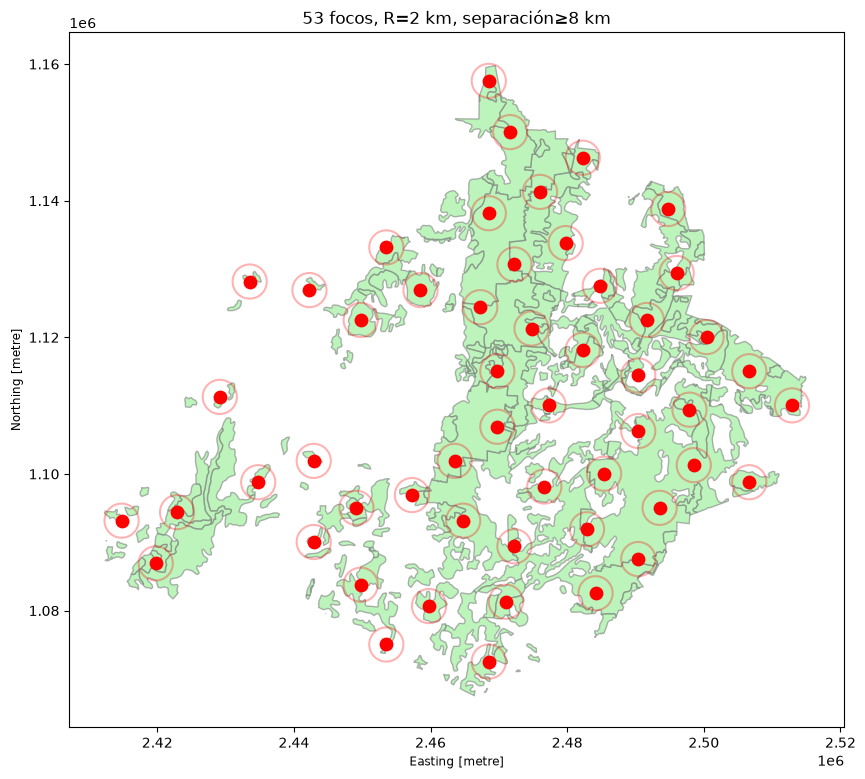

In [53]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

agro_map.plot(ax=ax, color="lightgreen", edgecolor="grey", alpha=0.6)
gdf_focos.plot(ax=ax, color="red", markersize=80, zorder=5)

# Opcional: círculos de cobertura de radio R
for p in gdf_focos.geometry:
    circle = p.buffer(R, resolution=32)
    gpd.GeoSeries([circle]).boundary.plot(ax=ax, color="red", alpha=0.3)

ax.set_title(f"{len(gdf_focos)} focos, R={R/1000:.0f} km, separación≥{D_MIN/1000:.0f} km")
plt.show()

## Serie II

In [ ]:
os.makedirs(MAPS_ROUTE/ "m2", exist_ok=True)
with ZipFile(MAPS_FOLDER / maps[1], 'r') as file:
    file.extractall(MAPS_ROUTE /"m2")

Vemos que la serie 2 tiene varios archivos. Vamos a revisar cada uno. 

In [ ]:
serie2_folder = "/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/m2/conjunto_de_datos"
serie2_maps = [f for f in os.listdir(serie2_folder) if f.endswith(".shp")]
serie2_maps

In [ ]:
maps201 = f"{serie2_folder}/{serie2_maps[0]}"
print(maps201)
map21 = gpd.read_file(maps201)
map21.shape

In [ ]:
map21.head()

Vemos que esto corresponde a la actividad pecuaria. Entonces, debemos buscar el agricola

In [ ]:
maps202 = f"{serie2_folder}/{serie2_maps[3]}"
print(maps202)
map22 = gpd.read_file(maps202)
map22.shape

In [ ]:
map22['ENTIDAD'].unique()

In [ ]:
maps203 = f"{serie2_folder}/{serie2_maps[4]}"
print(maps203)
map23 = gpd.read_file(maps203)
map23.shape

In [ ]:
map23['ENTIDAD'].unique()

Ahora juntaremos y filtraremos la parte agricola.

In [ ]:
import pandas as pd

agro2 = map23[map23['ENTIDAD'] == "AREA AGRICOLA"]
print(agro2.shape)

print(agro2.columns)
print(map22.columns)
agro2 = pd.concat([agro2, map22])
print(agro2.shape)

In [ ]:
agro2.plot()

### Serie I vs Serie II.

Notemos que los datos no son los mismos. 

In [ ]:
agro1.shape, agro2.shape

Para construir unos datos. Partiremos construyendo un conjutno de puntos a partir de Serie I. En nuestro caso, usaremos el centro de cada región.

In [ ]:
agro1['SerieIPoints'] = agro1['geometry'].centroid
agro2['SerieIIPoints'] = agro2['geometry'].centroid

In [ ]:
agroset1 = [p.coords[0] for p in agro1['SerieIPoints']]
agroset2 = [p.coords[0] for p in agro2['SerieIIPoints']]


In [ ]:
import numpy as np

def euclidean(p1, p2):
    gy = p2[1] - p1[1]
    gx = p2[0] - p1[0]
    dis = (gy ** 2 + gx**2 ) ** (0.5)
    return dis

v = np.zeros((len(agroset1), len(agroset2)))

k=0
for k1, p1 in enumerate(agroset1):
    for k2, p2 in enumerate(agroset2):
        v[k1, k2] = euclidean(p1, p2)
    print(k)
    k+=1
    

In [ ]:
v